# Summary Plot

Load precomputed layerwise summaries and plot the main regression/RSA/RDM figures without recomputing analyses.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd

PROJECT_ROOT = Path.cwd().resolve()
while not (PROJECT_ROOT / 'ismir2026' / 'natural_sound_align').exists() and PROJECT_ROOT != PROJECT_ROOT.parent:
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from ismir2026.natural_sound_align.cache_summary import COMPILED_ROOT, load_compiled_summaries, load_cached_rsa_payload, select_plot_summary
from ismir2026.natural_sound_align.rsa import plot_model_vs_human_rdm

dataset = 'NH2015'  # 'NH2015', 'N2015', or 'B2021'
layer_mode = 'best'  # 'final' or 'best'
layerwise_model = 'CLAP'  # e.g. 'CLAP', 'CLAP_MUSIC', 'CLAP_MUSIC_SPEECH', 'MULAN', 'MERT', 'MERT95', 'WAV2VEC2', 'MUSICGEN_SMALL', 'MUSICGEN_MEDIUM', 'MUSICGEN_LARGE', or 'MUSICGEN_MELODY_LARGE'

regression_all, rsa_all = load_compiled_summaries(compiled_root=COMPILED_ROOT)

available_models = sorted(set(regression_all['model_name'].unique()) & set(rsa_all['model_name'].unique()))
if available_models and layerwise_model not in available_models:
    print(f"Requested model '{layerwise_model}' not found in compiled summaries. Using '{available_models[0]}' instead.")
    layerwise_model = available_models[0]


def resolve_dataset(requested, regression_table, rsa_table, model_name=None):
    reg_sets = set(regression_table['dataset_name'].unique())
    rsa_sets = set(rsa_table['dataset_name'].unique())
    if model_name is not None:
        reg_sets = set(regression_table.query("model_name == @model_name")['dataset_name'].unique())
        rsa_sets = set(rsa_table.query("model_name == @model_name")['dataset_name'].unique())
        if not reg_sets or not rsa_sets:
            reg_sets = set(regression_table['dataset_name'].unique())
            rsa_sets = set(rsa_table['dataset_name'].unique())
    available = sorted(reg_sets & rsa_sets)
    if not available:
        raise ValueError('No overlapping datasets between regression and RSA tables.')
    if requested not in available:
        print(f"Requested dataset '{requested}' not found for model '{model_name}'. Using '{available[0]}' instead.")
        return available[0]
    return requested


dataset = resolve_dataset(dataset, regression_all, rsa_all, model_name=layerwise_model)

regression_summary = select_plot_summary(
    regression_all,
    dataset_name=dataset,
    layer_mode=layer_mode,
    metric_column='cv_subject_mean',
)
rsa_summary = select_plot_summary(
    rsa_all,
    dataset_name=dataset,
    layer_mode=layer_mode,
    metric_column='median_spearman',
)

foundation_regression = regression_summary.query("model_name != 'SPECTEMP'").reset_index(drop=True)
spectemp_regression = regression_summary.query("model_name == 'SPECTEMP'").reset_index(drop=True)
foundation_rsa = rsa_summary.query("model_name != 'SPECTEMP'").reset_index(drop=True)
spectemp_rsa = rsa_summary.query("model_name == 'SPECTEMP'").reset_index(drop=True)

layer_mode_label = 'Best layer' if layer_mode == 'best' else 'Final layer'

display(regression_summary)
display(rsa_summary)


,model_name,representation_name,n_voxels,n_splits,source_dim,median_noise_corrected_r2,mean_noise_corrected_r2,median_noise_corrected_r2_raw,mean_noise_corrected_r2_raw,median_r2,...,cv_subject_mean,cv_subject_median,cv_subject_sem,cv_subject_std,value_column,dataset_name,layer_index,layer_depth,is_final,result_dir
0,MULAN,layer_09,7694,10,1024,0.765762,0.721824,0.765762,0.770365,0.346425,...,0.761989,0.758771,0.014229,0.040247,median_r2_test_c,NH2015,9.0,9,False,/home/hjkim/selective_auditory/ismir2026/natur...
1,MERT,layer_05,7694,10,1024,0.749149,0.718122,0.749149,0.794878,0.343446,...,0.753849,0.747028,0.022300,0.063074,median_r2_test_c,NH2015,5.0,5,False,/home/hjkim/selective_auditory/ismir2026/natur...
2,CLAP,layer_03,7694,10,768,0.751750,0.721248,0.751750,0.776488,0.341161,...,0.750429,0.745370,0.016307,0.046123,median_r2_test_c,NH2015,3.0,3,False,/home/hjkim/selective_auditory/ismir2026/natur...
3,MERT95,layer_05,7694,10,768,0.735700,0.710898,0.735700,0.764776,0.346186,...,0.740025,0.731421,0.021279,0.060186,median_r2_test_c,NH2015,5.0,5,False,/home/hjkim/selective_auditory/ismir2026/natur...
4,CLAP_MUSIC_SPEECH,layer_03,7694,10,1024,0.732772,0.699986,0.732772,0.748630,0.318240,...,0.728712,0.729563,0.023148,0.065474,median_r2_test_c,NH2015,3.0,3,False,/home/hjkim/selective_auditory/ismir2026/natur...
5,MUSICGEN_SMALL,layer_10,7694,10,1024,0.658713,0.658327,0.658713,0.734803,0.303598,...,0.661185,0.662964,0.016581,0.046899,median_r2_test_c,NH2015,10.0,10,False,/home/hjkim/selective_auditory/ismir2026/natur...
6,MUSICGEN_LARGE,layer_34,7694,10,2048,0.609617,0.606027,0.609617,0.662714,0.270298,...,0.610923,0.616054,0.020342,0.057535,median_r2_test_c,NH2015,34.0,34,False,/home/hjkim/selective_auditory/ismir2026/natur...
7,MUSICGEN_MELODY_LARGE,layer_46,7694,10,2048,0.602491,0.598647,0.602491,0.658540,0.240379,...,0.604326,0.598324,0.023068,0.065246,median_r2_test_c,NH2015,46.0,46,False,/home/hjkim/selective_auditory/ismir2026/natur...
8,MUSICGEN_MEDIUM,layer_30,7694,10,1536,0.577550,0.577631,0.577550,0.628734,0.249882,...,0.579778,0.593415,0.025802,0.072979,median_r2_test_c,NH2015,30.0,30,False,/home/hjkim/selective_auditory/ismir2026/natur...
9,SPECTEMP,avgpool,7694,10,23421,0.542200,0.544965,0.542200,0.597126,0.211782,...,0.548215,0.554878,0.019209,0.054331,median_r2_test_c,NH2015,NaN,0,False,/home/hjkim/selective_auditory/ismir2026/natur...


,model_name,representation_name,n_repetitions,n_participants,n_splits,mean_spearman,median_spearman,participant_sem,mean_leave_one_out_neural_spearman,dataset_name,layer_index,layer_depth,is_final,result_dir
0,MERT,layer_04,8,8,10,0.504783,0.510128,0.009904,0.754764,NH2015,4.0,4,False,/home/hjkim/selective_auditory/ismir2026/natur...
1,MERT95,layer_05,8,8,10,0.497703,0.497986,0.006947,0.754764,NH2015,5.0,5,False,/home/hjkim/selective_auditory/ismir2026/natur...
2,MULAN,layer_06,8,8,10,0.476230,0.480516,0.007083,0.754764,NH2015,6.0,6,False,/home/hjkim/selective_auditory/ismir2026/natur...
3,CLAP_MUSIC_SPEECH,layer_03,8,8,10,0.425292,0.431201,0.006857,0.754764,NH2015,3.0,3,False,/home/hjkim/selective_auditory/ismir2026/natur...
4,CLAP,layer_02,8,8,10,0.421643,0.420338,0.005212,0.754764,NH2015,2.0,2,False,/home/hjkim/selective_auditory/ismir2026/natur...
5,SPECTEMP,avgpool,8,8,10,0.412462,0.410600,0.011872,0.754764,NH2015,NaN,0,False,/home/hjkim/selective_auditory/ismir2026/natur...
6,MUSICGEN_SMALL,layer_14,8,8,10,0.370816,0.363087,0.014120,0.754764,NH2015,14.0,14,False,/home/hjkim/selective_auditory/ismir2026/natur...
7,MUSICGEN_LARGE,layer_34,8,8,10,0.350769,0.342905,0.008705,0.754764,NH2015,34.0,34,False,/home/hjkim/selective_auditory/ismir2026/natur...
8,MUSICGEN_MELODY_LARGE,layer_47,8,8,10,0.331592,0.326455,0.012353,0.754764,NH2015,47.0,47,False,/home/hjkim/selective_auditory/ismir2026/natur...
9,MUSICGEN_MEDIUM,layer_30,8,8,10,0.296089,0.287198,0.008315,0.754764,NH2015,30.0,30,False,/home/hjkim/selective_auditory/ismir2026/natur...


## Regression Summary

,dataset_name,model_name,representation_name,cv_subject_mean,cv_subject_median,median_noise_corrected_r2
0,NH2015,MULAN,layer_09,0.761989,0.758771,0.765762
1,NH2015,MERT,layer_05,0.753849,0.747028,0.749149
2,NH2015,CLAP,layer_03,0.750429,0.745370,0.751750
3,NH2015,MERT95,layer_05,0.740025,0.731421,0.735700
4,NH2015,CLAP_MUSIC_SPEECH,layer_03,0.728712,0.729563,0.732772
5,NH2015,MUSICGEN_SMALL,layer_10,0.661185,0.662964,0.658713
6,NH2015,MUSICGEN_LARGE,layer_34,0.610923,0.616054,0.609617
7,NH2015,MUSICGEN_MELODY_LARGE,layer_46,0.604326,0.598324,0.602491
8,NH2015,MUSICGEN_MEDIUM,layer_30,0.579778,0.593415,0.577550
9,NH2015,SPECTEMP,avgpool,0.548215,0.554878,0.542200


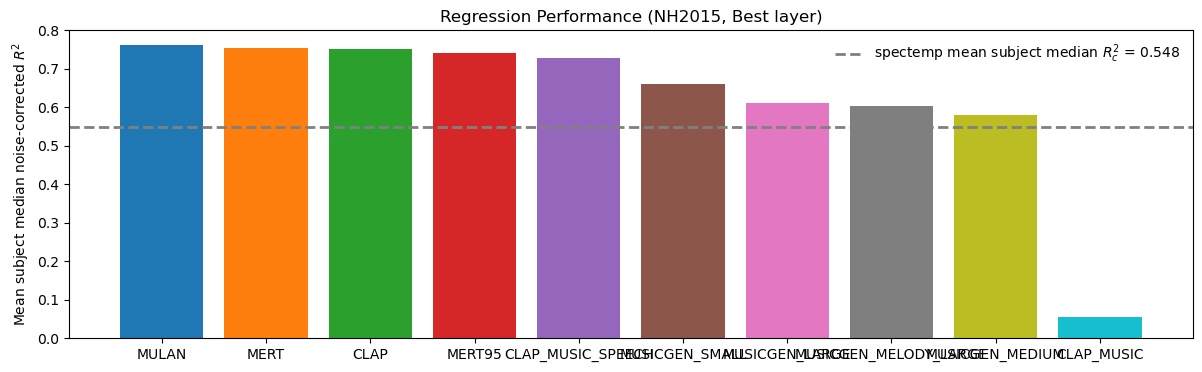

In [2]:
display(regression_summary[['dataset_name', 'model_name', 'representation_name', 'cv_subject_mean', 'cv_subject_median', 'median_noise_corrected_r2']])

baseline_subject_mean = float(spectemp_regression['cv_subject_mean'].iloc[0]) if len(spectemp_regression) else None

fig_width = max(7, 1.25 * len(foundation_regression) + 2)
fig, ax = plt.subplots(figsize=(fig_width, 4))
palette = list(plt.get_cmap('tab10').colors) + list(plt.get_cmap('Set2').colors)
ax.bar(foundation_regression['model_name'], foundation_regression['cv_subject_mean'], color=palette[:len(foundation_regression)])
if baseline_subject_mean is not None:
    ax.axhline(baseline_subject_mean, linestyle='--', color='gray', linewidth=2, label=f"spectemp mean subject median $R^2_c$ = {baseline_subject_mean:.3f}")
    ax.legend(frameon=False)
ax.set_ylabel('Mean subject median noise-corrected $R^2$')
ax.set_title(f'Regression Performance ({dataset}, {layer_mode_label})')
plt.show()


,representation_name,layer_depth,cv_subject_mean,median_noise_corrected_r2,is_final
0,layer_00,0,0.015822,0.010231,False
1,layer_01,1,0.571511,0.573594,False
2,layer_02,2,0.712435,0.714342,False
3,layer_03,3,0.750429,0.751750,False
4,layer_04,4,0.701302,0.708497,False
5,final,5,0.696856,0.702076,True


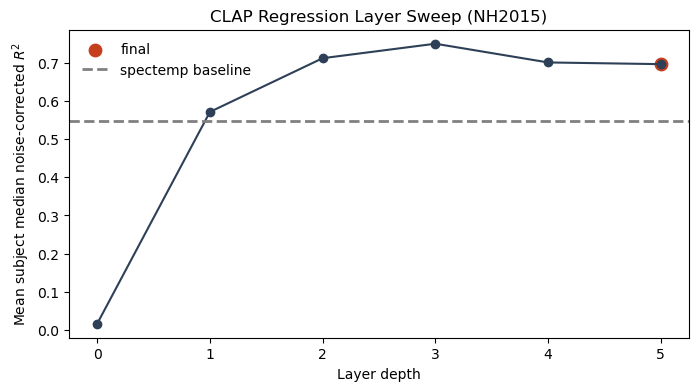

In [3]:
regression_layerwise = regression_all.query("dataset_name == @dataset and model_name == @layerwise_model").sort_values('layer_depth').reset_index(drop=True)
plot_regression_layerwise = regression_layerwise.copy()
if (plot_regression_layerwise['layer_depth'] < 0).any():
    nonfinal_depths = plot_regression_layerwise.loc[~plot_regression_layerwise['is_final'], 'layer_depth']
    fallback_depth = int(nonfinal_depths.max()) + 1 if len(nonfinal_depths) else 0
    plot_regression_layerwise.loc[plot_regression_layerwise['is_final'], 'layer_depth'] = fallback_depth
display(plot_regression_layerwise[['representation_name', 'layer_depth', 'cv_subject_mean', 'median_noise_corrected_r2', 'is_final']])

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(plot_regression_layerwise['layer_depth'], plot_regression_layerwise['cv_subject_mean'], marker='o', color='#2E4057')
final_row = plot_regression_layerwise.query('is_final').iloc[0]
ax.scatter([final_row['layer_depth']], [final_row['cv_subject_mean']], color='#C73E1D', s=80, label='final')
if len(spectemp_regression):
    ax.axhline(float(spectemp_regression['cv_subject_mean'].iloc[0]), linestyle='--', color='gray', linewidth=2, label='spectemp baseline')
ax.set_xticks(plot_regression_layerwise['layer_depth'])
ax.set_xlabel('Layer depth')
ax.set_ylabel('Mean subject median noise-corrected $R^2$')
ax.set_title(f'{layerwise_model} Regression Layer Sweep ({dataset})')
ax.legend(frameon=False)
plt.show()


## RSA Summary

,dataset_name,model_name,representation_name,mean_spearman,median_spearman,n_participants
0,NH2015,MERT,layer_04,0.504783,0.510128,8
1,NH2015,MERT95,layer_05,0.497703,0.497986,8
2,NH2015,MULAN,layer_06,0.476230,0.480516,8
3,NH2015,CLAP_MUSIC_SPEECH,layer_03,0.425292,0.431201,8
4,NH2015,CLAP,layer_02,0.421643,0.420338,8
5,NH2015,SPECTEMP,avgpool,0.412462,0.410600,8
6,NH2015,MUSICGEN_SMALL,layer_14,0.370816,0.363087,8
7,NH2015,MUSICGEN_LARGE,layer_34,0.350769,0.342905,8
8,NH2015,MUSICGEN_MELODY_LARGE,layer_47,0.331592,0.326455,8
9,NH2015,MUSICGEN_MEDIUM,layer_30,0.296089,0.287198,8


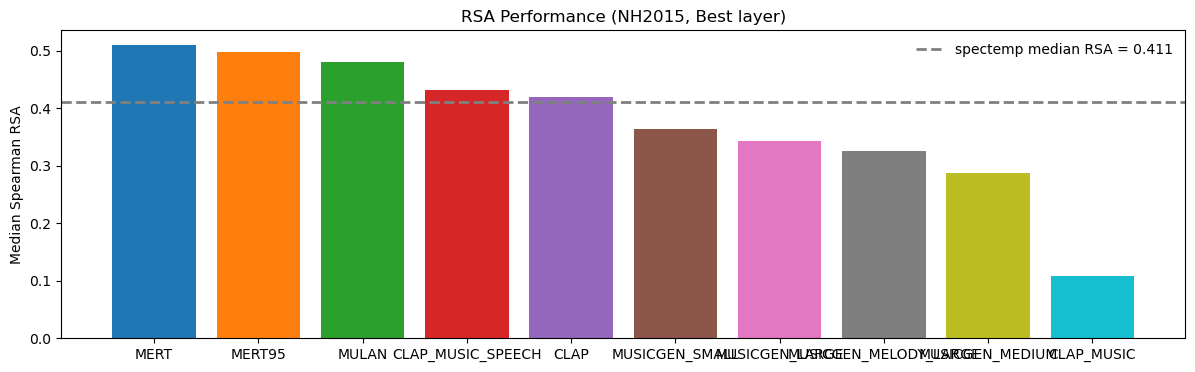

In [4]:
display(rsa_summary[['dataset_name', 'model_name', 'representation_name', 'mean_spearman', 'median_spearman', 'n_participants']])

fig_width = max(7, 1.25 * len(foundation_rsa) + 2)
fig, ax = plt.subplots(figsize=(fig_width, 4))
palette = list(plt.get_cmap('tab10').colors) + list(plt.get_cmap('Set2').colors)
ax.bar(foundation_rsa['model_name'], foundation_rsa['median_spearman'], color=palette[:len(foundation_rsa)])
if len(spectemp_rsa):
    baseline_rsa = float(spectemp_rsa['median_spearman'].iloc[0])
    ax.axhline(baseline_rsa, linestyle='--', color='gray', linewidth=2, label=f"spectemp median RSA = {baseline_rsa:.3f}")
    ax.legend(frameon=False)
ax.set_ylabel('Median Spearman RSA')
ax.set_title(f'RSA Performance ({dataset}, {layer_mode_label})')
plt.show()


,representation_name,layer_depth,median_spearman,mean_spearman,is_final
0,layer_00,0,0.057851,0.067755,False
1,layer_01,1,0.401402,0.397860,False
2,layer_02,2,0.420338,0.421643,False
3,layer_03,3,0.410127,0.406921,False
4,layer_04,4,0.376606,0.372732,False
5,final,5,0.381570,0.377013,True


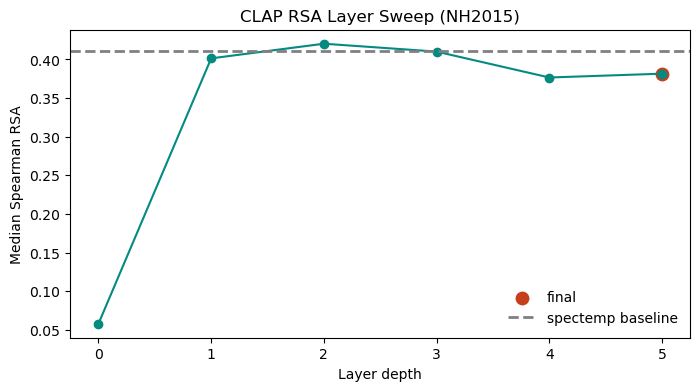

In [5]:
rsa_layerwise = rsa_all.query("dataset_name == @dataset and model_name == @layerwise_model").sort_values('layer_depth').reset_index(drop=True)
plot_rsa_layerwise = rsa_layerwise.copy()
if (plot_rsa_layerwise['layer_depth'] < 0).any():
    nonfinal_depths = plot_rsa_layerwise.loc[~plot_rsa_layerwise['is_final'], 'layer_depth']
    fallback_depth = int(nonfinal_depths.max()) + 1 if len(nonfinal_depths) else 0
    plot_rsa_layerwise.loc[plot_rsa_layerwise['is_final'], 'layer_depth'] = fallback_depth
display(plot_rsa_layerwise[['representation_name', 'layer_depth', 'median_spearman', 'mean_spearman', 'is_final']])

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(plot_rsa_layerwise['layer_depth'], plot_rsa_layerwise['median_spearman'], marker='o', color='#048A81')
final_row = plot_rsa_layerwise.query('is_final').iloc[0]
ax.scatter([final_row['layer_depth']], [final_row['median_spearman']], color='#C73E1D', s=80, label='final')
if len(spectemp_rsa):
    ax.axhline(float(spectemp_rsa['median_spearman'].iloc[0]), linestyle='--', color='gray', linewidth=2, label='spectemp baseline')
ax.set_xticks(plot_rsa_layerwise['layer_depth'])
ax.set_xlabel('Layer depth')
ax.set_ylabel('Median Spearman RSA')
ax.set_title(f'{layerwise_model} RSA Layer Sweep ({dataset})')
ax.legend(frameon=False)
plt.show()


## Human vs Model RDM

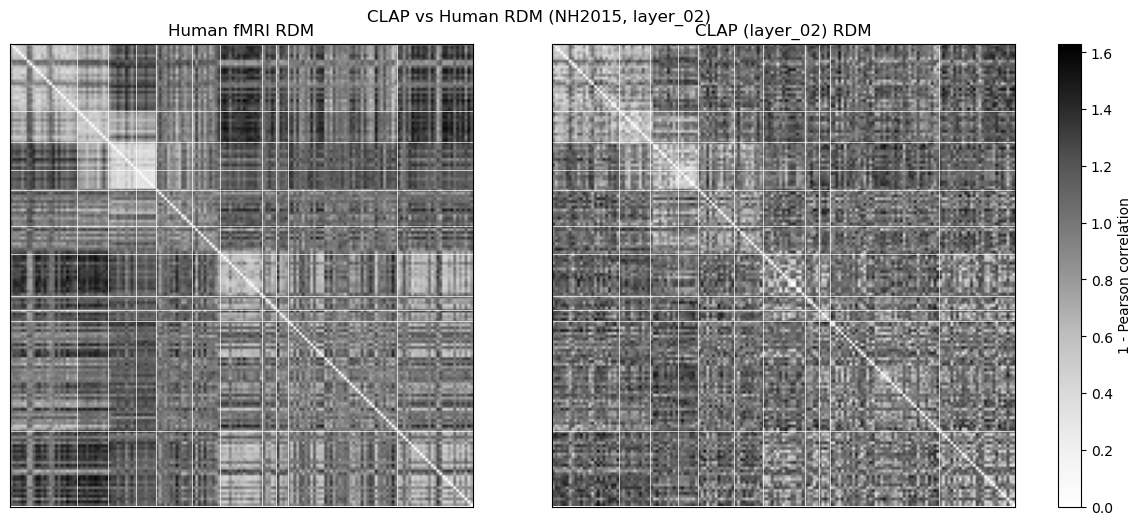

In [6]:
summary_source = rsa_summary if layer_mode == 'best' else rsa_all.query("dataset_name == @dataset and model_name == @layerwise_model and is_final")
if layer_mode == 'best':
    selected_row = summary_source.query("model_name == @layerwise_model").iloc[0]
else:
    selected_row = summary_source.iloc[0]

payload = load_cached_rsa_payload(
    dataset_name=dataset,
    model_name=layerwise_model,
    representation_name=str(selected_row['representation_name']),
)

fig, axes = plot_model_vs_human_rdm(
    payload['model_correlation_matrix'],
    payload['mean_human_correlation_matrix'],
    payload['metadata'],
    model_name=f"{layerwise_model} ({selected_row['representation_name']})",
    reorder_by_category=True,
)
fig.suptitle(f"{layerwise_model} vs Human RDM ({dataset}, {selected_row['representation_name']})", y=1.02)
plt.show()


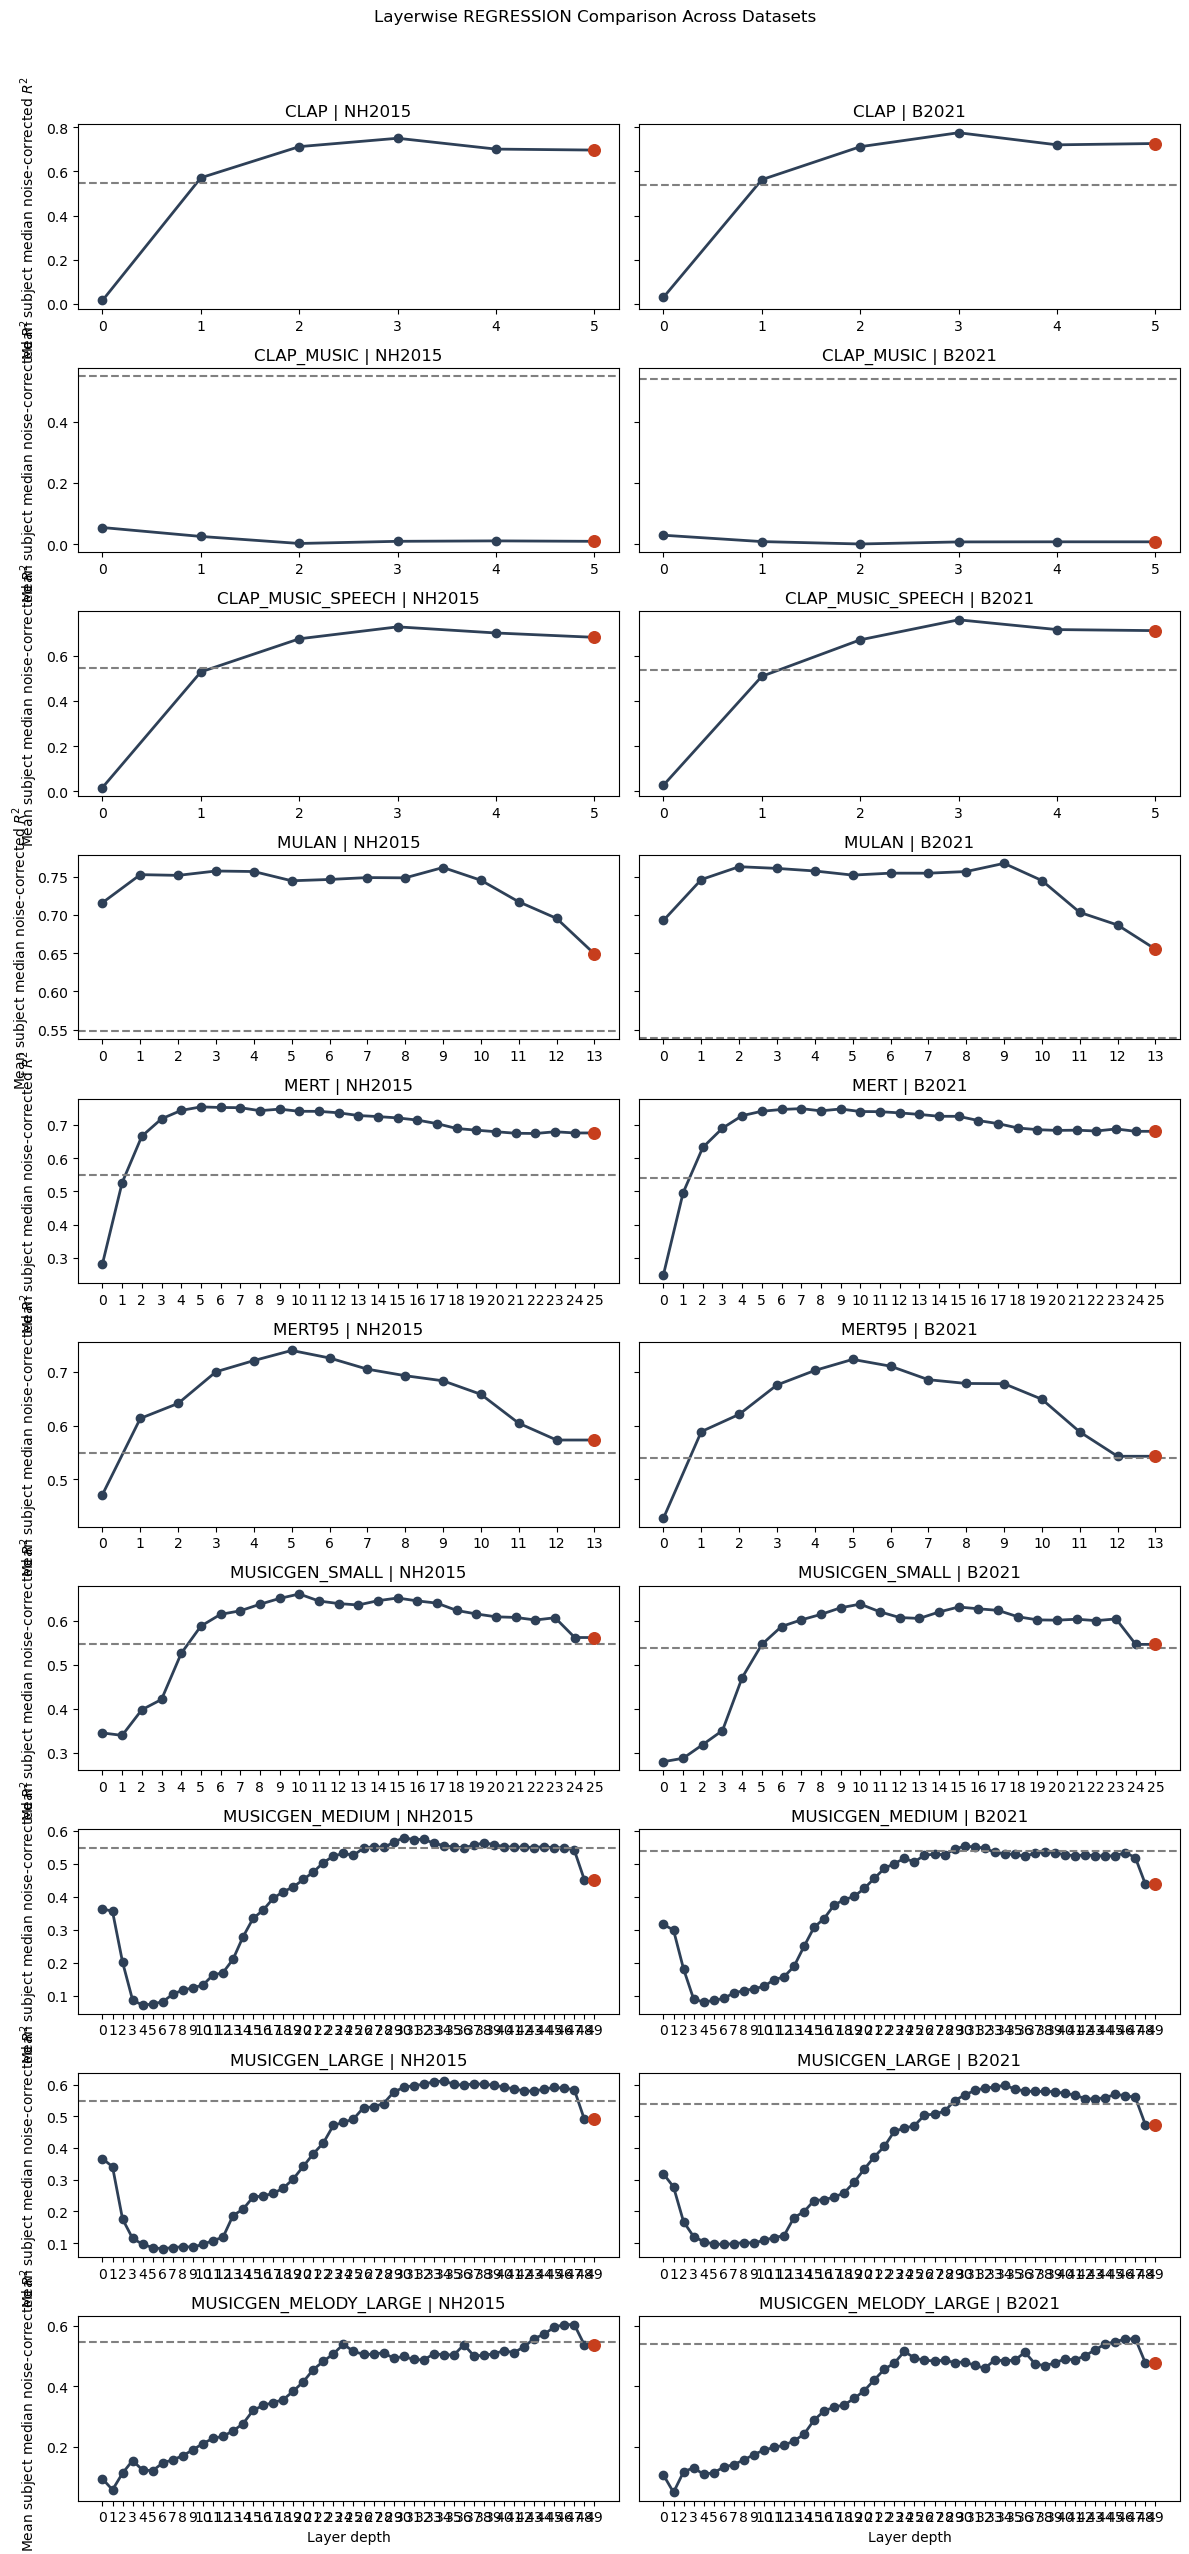

In [10]:
comparison_mode = 'regression'  # 'regression' or 'RSA'

mode_key = comparison_mode.strip().lower()
if mode_key == 'regression':
    layerwise_table = regression_all
    metric_column = 'cv_subject_mean'
    y_label = 'Mean subject median noise-corrected $R^2$'
    line_color = '#2E4057'
elif mode_key == 'rsa':
    layerwise_table = rsa_all
    metric_column = 'median_spearman'
    y_label = 'Median Spearman RSA'
    line_color = '#048A81'
else:
    raise ValueError("comparison_mode must be either 'regression' or 'RSA'.")

default_model_order = ['CLAP', 'CLAP_MUSIC', 'CLAP_MUSIC_SPEECH', 'MULAN', 'MERT', 'MERT95', 'WAV2VEC2', 'MUSICGEN_SMALL', 'MUSICGEN_MEDIUM', 'MUSICGEN_LARGE', 'MUSICGEN_MELODY_LARGE']
available_models = [model for model in default_model_order if model in layerwise_table['model_name'].unique()]
comparison_models = available_models  # replace with a custom list if you want a subset

if not comparison_models:
    raise ValueError('No models available for comparison in the compiled summaries.')

model_dataset_sets = []
for model_name in comparison_models:
    datasets_for_model = set(layerwise_table.query("model_name == @model_name")['dataset_name'].unique())
    if datasets_for_model:
        model_dataset_sets.append(datasets_for_model)

if model_dataset_sets:
    datasets = sorted(set.intersection(*model_dataset_sets))
else:
    datasets = []

if not datasets:
    datasets = sorted(layerwise_table['dataset_name'].unique())
    print("No common datasets across selected models. Plotting all available datasets instead:", datasets)

fig_height = max(10, 2.5 * len(comparison_models))
fig_width = max(10, 4 * len(datasets))
fig, axes = plt.subplots(nrows=len(comparison_models), ncols=len(datasets), figsize=(fig_width, fig_height), sharex=False, sharey='row', squeeze=False)

for row_index, model_name in enumerate(comparison_models):
    for col_index, dataset_name in enumerate(datasets):
        ax = axes[row_index, col_index]
        layerwise = layerwise_table.query("dataset_name == @dataset_name and model_name == @model_name").sort_values('layer_depth').reset_index(drop=True).copy()
        if layerwise.empty:
            ax.set_axis_off()
            continue
        if (layerwise['layer_depth'] < 0).any():
            nonfinal_depths = layerwise.loc[~layerwise['is_final'], 'layer_depth']
            fallback_depth = int(nonfinal_depths.max()) + 1 if len(nonfinal_depths) else 0
            layerwise.loc[layerwise['is_final'], 'layer_depth'] = fallback_depth

        ax.plot(layerwise['layer_depth'], layerwise[metric_column], marker='o', color=line_color, linewidth=2)
        final_row = layerwise.query('is_final').iloc[0]
        ax.scatter([final_row['layer_depth']], [final_row[metric_column]], color='#C73E1D', s=70, zorder=3)

        baseline_row = layerwise_table.query("dataset_name == @dataset_name and model_name == 'SPECTEMP'")
        if len(baseline_row):
            ax.axhline(float(baseline_row.iloc[0][metric_column]), linestyle='--', color='gray', linewidth=1.5)

        ax.set_title(f'{model_name} | {dataset_name}')
        ax.set_xticks(layerwise['layer_depth'])
        if row_index == len(comparison_models) - 1:
            ax.set_xlabel('Layer depth')
        if col_index == 0:
            ax.set_ylabel(y_label)

fig.suptitle(f'Layerwise {comparison_mode.upper()} Comparison Across Datasets', y=1.02)
fig.tight_layout()
plt.show()


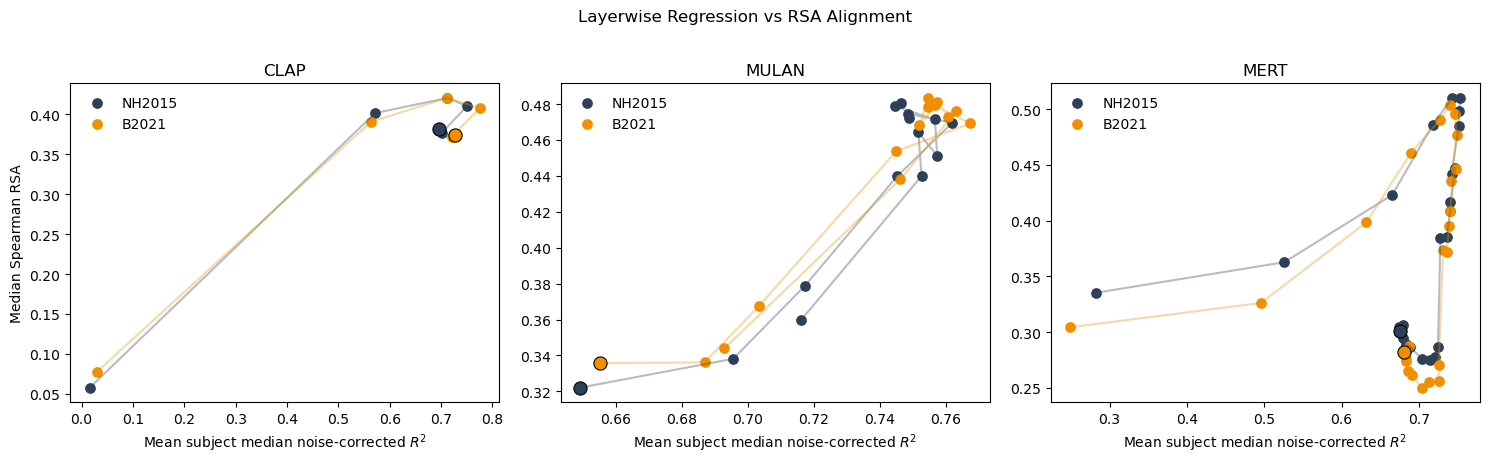

In [8]:
layer_alignment = regression_all[
    ['dataset_name', 'model_name', 'representation_name', 'layer_depth', 'is_final', 'cv_subject_mean']
].merge(
    rsa_all[['dataset_name', 'model_name', 'representation_name', 'layer_depth', 'is_final', 'median_spearman']],
    on=['dataset_name', 'model_name', 'representation_name', 'layer_depth', 'is_final'],
    how='inner',
)

dataset_colors = {'NH2015': '#2E4057', 'B2021': '#F18F01'}
alignment_models = ['CLAP', 'MULAN', 'MERT']  # e.g. ['CLAP_MUSIC', 'CLAP_MUSIC_SPEECH', 'MERT95', 'MUSICGEN_SMALL', 'MUSICGEN_MEDIUM', 'MUSICGEN_LARGE', 'MUSICGEN_MELODY_LARGE']

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharex=False, sharey=False)

for axis, model_name in zip(axes, alignment_models):
    model_df = layer_alignment.query("model_name == @model_name").copy()
    for dataset_name, color in dataset_colors.items():
        dataset_df = model_df.query("dataset_name == @dataset_name").sort_values('layer_depth').reset_index(drop=True)
        axis.plot(dataset_df['cv_subject_mean'], dataset_df['median_spearman'], color=color, alpha=0.35, linewidth=1.5)
        axis.scatter(dataset_df['cv_subject_mean'], dataset_df['median_spearman'], color=color, s=45, label=dataset_name)
        final_df = dataset_df.query('is_final')
        if len(final_df):
            axis.scatter(final_df['cv_subject_mean'], final_df['median_spearman'], color=color, edgecolor='black', linewidth=0.8, s=90, zorder=3)

    axis.set_title(model_name)
    axis.set_xlabel('Mean subject median noise-corrected $R^2$')
    if model_name == alignment_models[0]:
        axis.set_ylabel('Median Spearman RSA')
    handles, labels = axis.get_legend_handles_labels()
    unique = dict(zip(labels, handles))
    axis.legend(unique.values(), unique.keys(), frameon=False)

fig.suptitle('Layerwise Regression vs RSA Alignment', y=1.02)
fig.tight_layout()
plt.show()
